In [23]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [11]:
df = pd.read_csv('credit_risk_dataset.csv')

# Remove duplicate records and create a debt-burden feature from the financial history.
df = df.drop_duplicates().copy()
df['loan_to_income'] = df['loan_amnt'] / df['person_income'].clip(lower=1)
df['income_after_loan'] = df['person_income'] - df['loan_amnt']

print(f'Dataset shape after removing duplicates: {df.shape}')

Dataset shape after removing duplicates: (32416, 14)


In [ ]:
print('Dataset overview:')
display(df.head())
print('\nTarget distribution:')
print(df['loan_status'].value_counts(normalize=True).rename({0: 'Good credit', 1: 'Credit risk'}))

Dataset Overview:
   person_age  person_income person_home_ownership  person_emp_length  \
0          22          59000                  RENT              123.0   
1          21           9600                   OWN                5.0   
2          25           9600              MORTGAGE                1.0   
3          23          65500                  RENT                4.0   
4          24          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
0    PERSONAL          D      35000          16.02            1   
1   EDUCATION          B       1000          11.14            0   
2     MEDICAL          C       5500          12.87            1   
3     MEDICAL          C      35000          15.23            1   
4     MEDICAL          C      35000          14.27            1   

   loan_percent_income cb_person_default_on_file  cb_person_cred_hist_length  
0                 0.59                         Y             

In [ ]:
print('Dataset information:')
df.info()
print('\nMissing values:')
print(df.isna().sum()[df.isna().sum() > 0])


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [12]:
target = 'loan_status'
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ]
)

print(f'Training rows: {len(X_train):,}')
print(f'Test rows: {len(X_test):,}')
print(f'Numeric features: {len(numeric_features)} | Categorical features: {len(categorical_features)}')

Training rows: 25,932
Test rows: 6,484
Numeric features: 9 | Categorical features: 4


In [24]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', random_forest)
])
random_forest_pipeline.fit(X_train, y_train)

fitted_models = {'Random Forest': random_forest_pipeline}
print('Random Forest trained successfully.')

Random Forest trained successfully.


In [25]:
results = []
for name, pipeline in fitted_models.items():
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
results_df.style.format({column: '{:.3f}' for column in results_df.columns if column != 'Model'})

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.920,0.863,0.753,0.804,0.926


In [27]:
print('Random Forest evaluation:')
display(results_df)

Random Forest evaluation:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.919803,0.862682,0.753173,0.804217,0.92571


In [28]:
best_model_name = results_df.loc[0, 'Model']
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print(f'Best model by ROC-AUC: {best_model_name}')
print(classification_report(
    y_test,
    best_predictions,
    target_names=['Good credit (0)', 'Credit risk (1)'],
    zero_division=0
))

Best model by ROC-AUC: Random Forest
                 precision    recall  f1-score   support

Good credit (0)       0.93      0.97      0.95      5066
Credit risk (1)       0.86      0.75      0.80      1418

       accuracy                           0.92      6484
      macro avg       0.90      0.86      0.88      6484
   weighted avg       0.92      0.92      0.92      6484



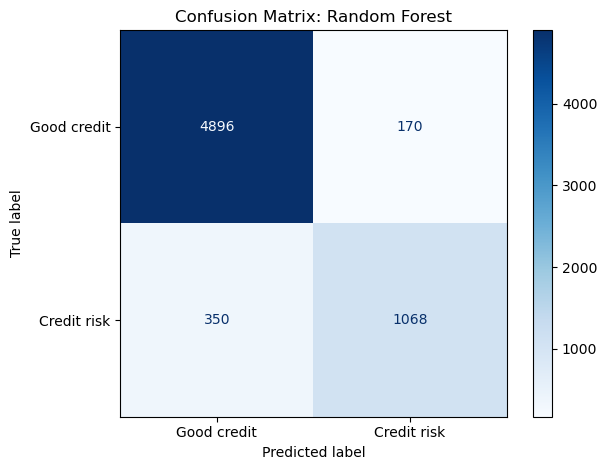

In [17]:
confusion_matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=['Good credit', 'Credit risk'],
    cmap='Blues'
)
confusion_matrix_display.ax_.set_title(f'Confusion Matrix: {best_model_name}')
plt.tight_layout()
plt.show()

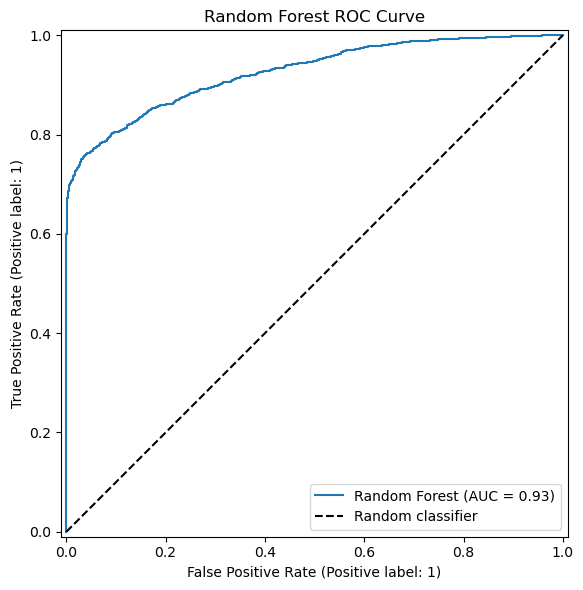

In [29]:
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_estimator(
    random_forest_pipeline,
    X_test,
    y_test,
    name='Random Forest',
    ax=plt.gca()
)
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.title('Random Forest ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
sample_input = pd.DataFrame([{
    'person_age': 30,
    'person_income': 60000,
    'person_home_ownership': 'RENT',
    'person_emp_length': 5.0,
    'loan_intent': 'PERSONAL',
    'loan_grade': 'B',
    'loan_amnt': 10000,
    'loan_int_rate': 11.5,
    'loan_percent_income': 0.17,
    'cb_person_default_on_file': 'N',
    'cb_person_cred_hist_length': 8,
    'loan_to_income': 10000 / 60000,
    'income_after_loan': 60000 - 10000
}])

sample_prediction = best_model.predict(sample_input)[0]
sample_probability = best_model.predict_proba(sample_input)[0, 1]
print(f'Predicted credit-risk probability: {sample_probability:.1%}')

Predicted credit-risk probability: 19.0%


In [20]:
print('Credit risk' if sample_prediction == 1 else 'Good credit')

Good credit


In [21]:
print('Interpretation: loan_status = 1 indicates a higher credit-risk outcome; loan_status = 0 indicates a lower-risk outcome.')

Interpretation: loan_status = 1 indicates a higher credit-risk outcome; loan_status = 0 indicates a lower-risk outcome.
